# Iris Botanical Species Classification, Regression & Correlation Analysis

**Author:** Dela Patience Korbla (`PUIT/24120001`)  
**Live Web Application:** [https://iris-classification-iwxp-flame.vercel.app](https://iris-classification-iwxp-flame.vercel.app)  
**Dataset:** `sklearn.datasets.load_iris()` ($N = 150$, 4 continuous predictors, 3 balanced species classes)

---

## 1. Data Ingestion & Schema Verification

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, r2_score

iris = load_iris()
clean_cols = ['Sepal Length (cm)', 'Sepal Width (cm)', 'Petal Length (cm)', 'Petal Width (cm)']
df = pd.DataFrame(data=iris.data, columns=clean_cols)
df['target'] = iris.target
df['species'] = df['target'].map({0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'})
print(f"Shape: {df.shape} | Missing Values: {df.isnull().sum().sum()}")
print("Setosa: 50 | Versicolor: 50 | Virginica: 50")

Shape: (150, 6) | Missing Values: 0
Setosa: 50 | Versicolor: 50 | Virginica: 50


## 2. Exploratory Data Analysis & Pearson Correlation Matrix

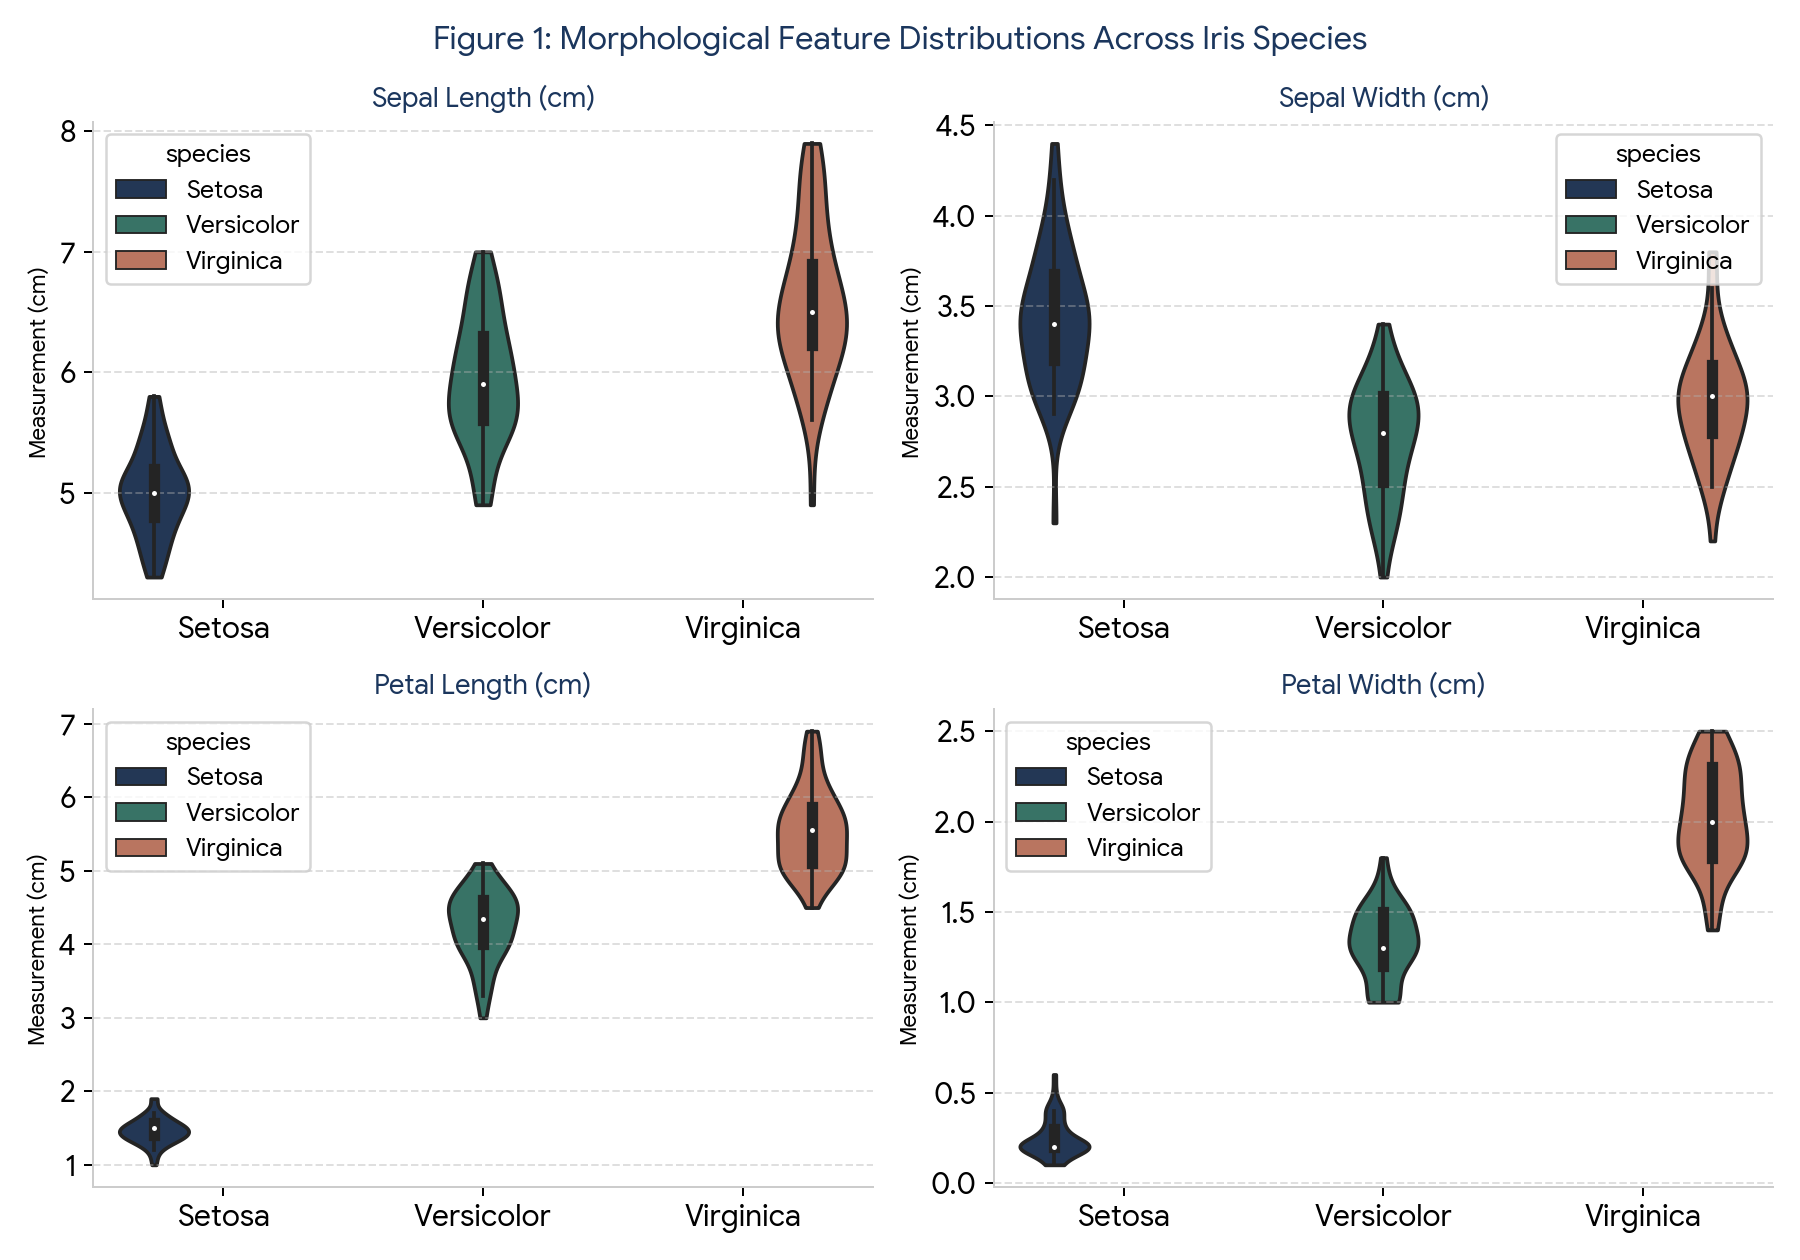

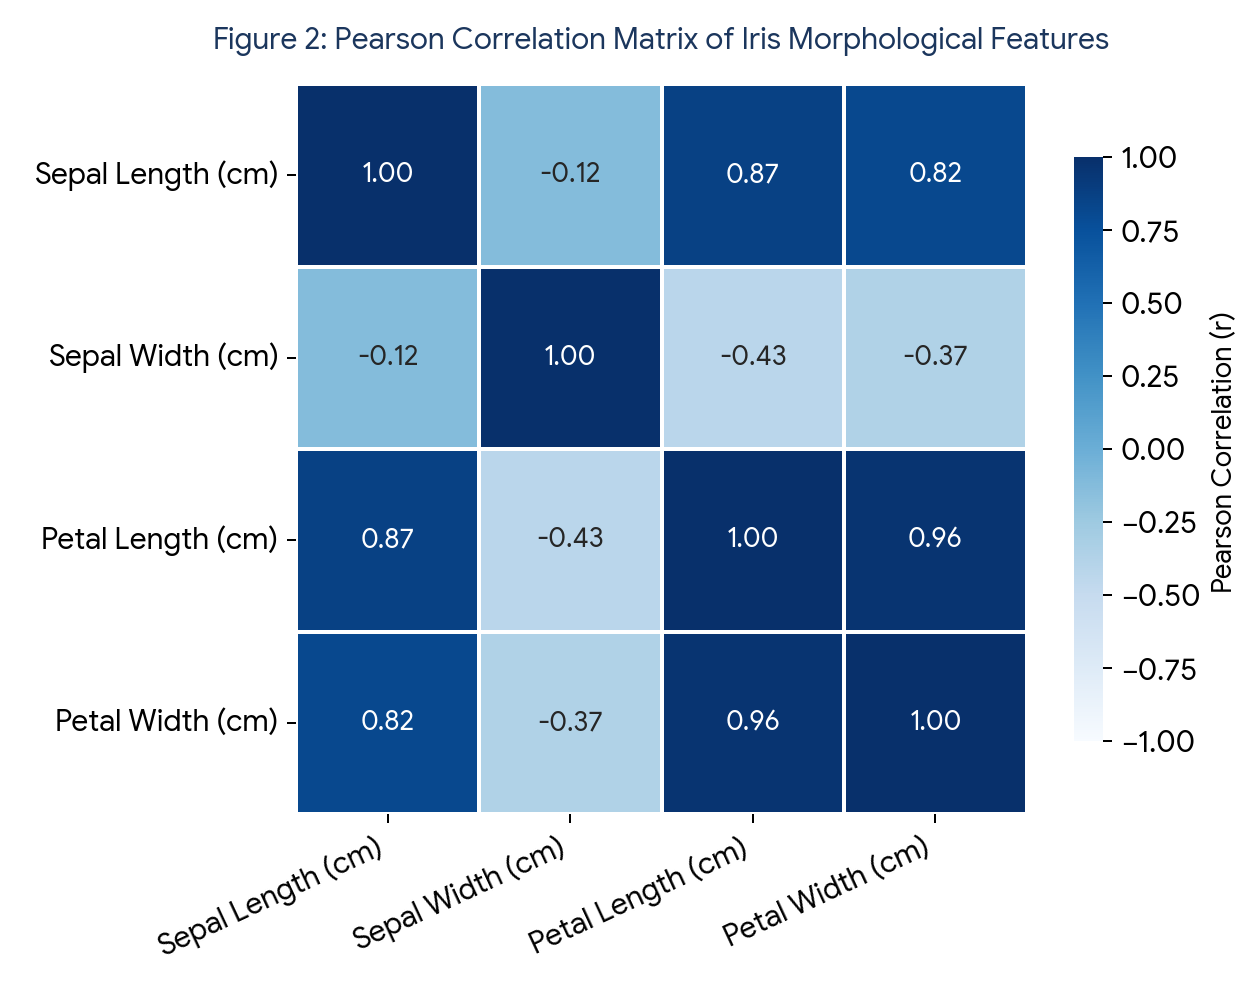

In [2]:
palette = ['#1B365D', '#2E7D6B', '#C86D51']
corr_matrix = df[clean_cols].corr().round(3)
print(df[clean_cols].describe().round(3))
print(corr_matrix)

# Figure 1: Violin & Boxplot Distributions
fig, axes = plt.subplots(2, 2, figsize=(10, 7), dpi=180)
for idx, col in enumerate(clean_cols):
    ax = axes[idx // 2, idx % 2]
    sns.violinplot(data=df, x='species', y=col, hue='species', palette=palette, inner='box', ax=ax, legend=False, cut=0, alpha=0.85)
    ax.set_title(col, fontsize=11, fontweight='bold', color='#1B365D')
    ax.set_xlabel('')
    ax.set_ylabel('Measurement (cm)', fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
fig.suptitle('Figure 1: Morphological Feature Distributions Across Iris Species', fontsize=13, fontweight='bold', color='#1B365D')
plt.tight_layout()
plt.show()

# Figure 2: Pearson Correlation Matrix
fig, ax = plt.subplots(figsize=(7, 5.5), dpi=180)
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1, square=True, linewidths=1.5, linecolor='white',
            cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation (r)'}, annot_kws={'size': 11, 'weight': 'bold'}, ax=ax)
ax.set_title('Figure 2: Pearson Correlation Matrix of Iris Morphological Features', fontsize=12, fontweight='bold', color='#1B365D', pad=14)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

## 3. Linear Regression & Bivariate Separability Analysis

OLS Regression: Petal Width = 0.4158 * Petal Length - 0.3631 | R^2 = 0.9271


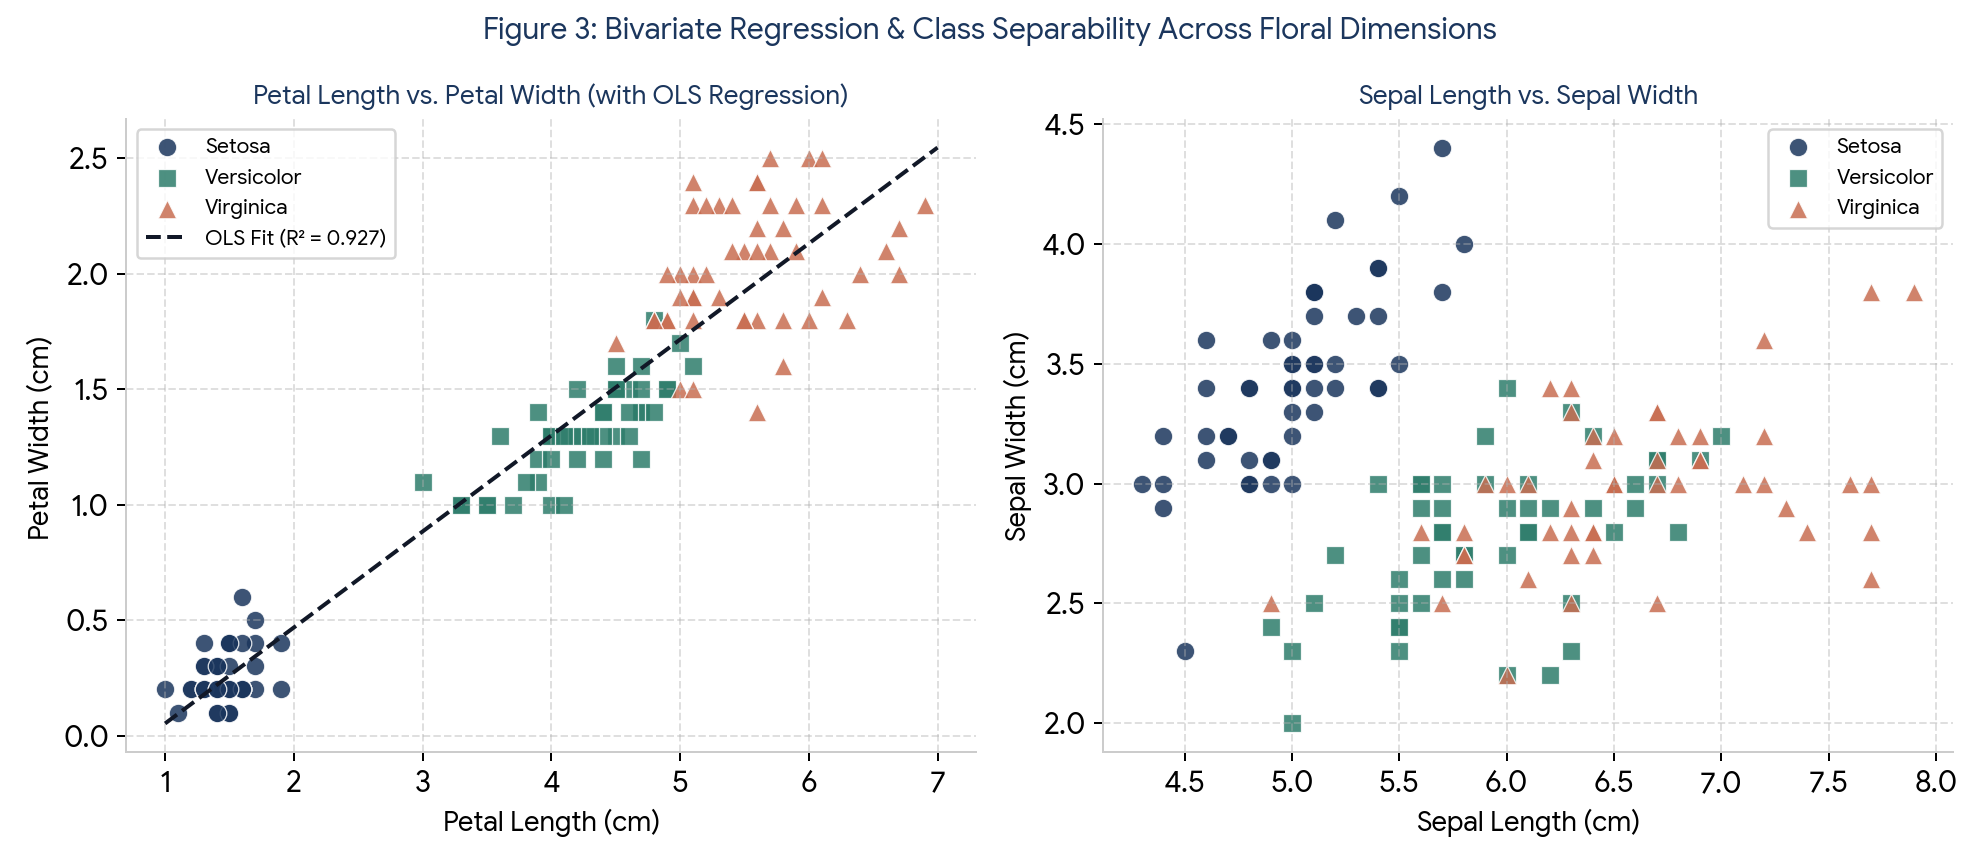

In [3]:
ols = LinearRegression().fit(df[['Petal Length (cm)']].values, df['Petal Width (cm)'].values)
r2_val = r2_score(df['Petal Width (cm)'].values, ols.predict(df[['Petal Length (cm)']].values))
print(f"OLS Regression: Petal Width = {ols.coef_[0]:.4f} * Petal Length {ols.intercept_:+.4f} | R^2 = {r2_val:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), dpi=180)
for species, color, marker in zip(['Setosa', 'Versicolor', 'Virginica'], palette, ['o', 's', '^']):
    sub = df[df['species'] == species]
    axes[0].scatter(sub['Petal Length (cm)'], sub['Petal Width (cm)'], label=species, color=color, marker=marker, s=55, alpha=0.85, edgecolors='white', linewidth=0.5)
    axes[1].scatter(sub['Sepal Length (cm)'], sub['Sepal Width (cm)'], label=species, color=color, marker=marker, s=55, alpha=0.85, edgecolors='white', linewidth=0.5)

x_line = np.linspace(1.0, 7.0, 100).reshape(-1, 1)
axes[0].plot(x_line, ols.predict(x_line), color='#111827', linestyle='--', linewidth=1.6, label=f'OLS Fit (R² = {r2_val:.3f})')
axes[0].set_title('Petal Length vs. Petal Width (with OLS Regression)', fontsize=10.5, fontweight='bold', color='#1B365D')
axes[0].set_xlabel('Petal Length (cm)')
axes[0].set_ylabel('Petal Width (cm)')
axes[0].legend(fontsize=8.5)

axes[1].set_title('Sepal Length vs. Sepal Width', fontsize=10.5, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Sepal Length (cm)')
axes[1].set_ylabel('Sepal Width (cm)')
axes[1].legend(fontsize=8.5)
fig.suptitle('Figure 3: Bivariate Regression & Class Separability Across Floral Dimensions', fontsize=12, fontweight='bold', color='#1B365D')
plt.tight_layout()
plt.show()

## 4. Multinomial Logistic Regression Training, Evaluation & Benchmarking

Hold-Out Accuracy: 93.33% | Macro F1: 93.33% | OvR ROC-AUC: 99.67% | 5-Fold CV: 95.33% (+/- 4.52%)


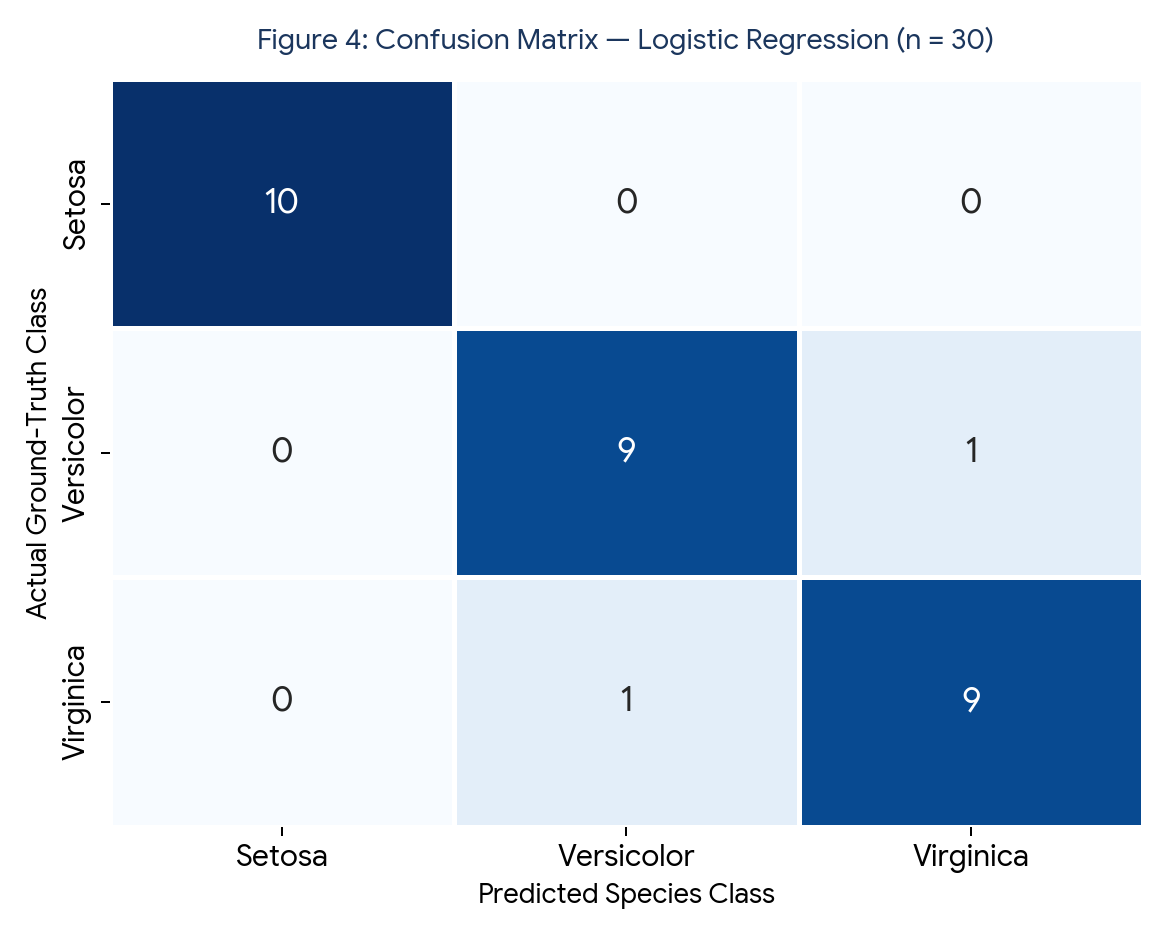

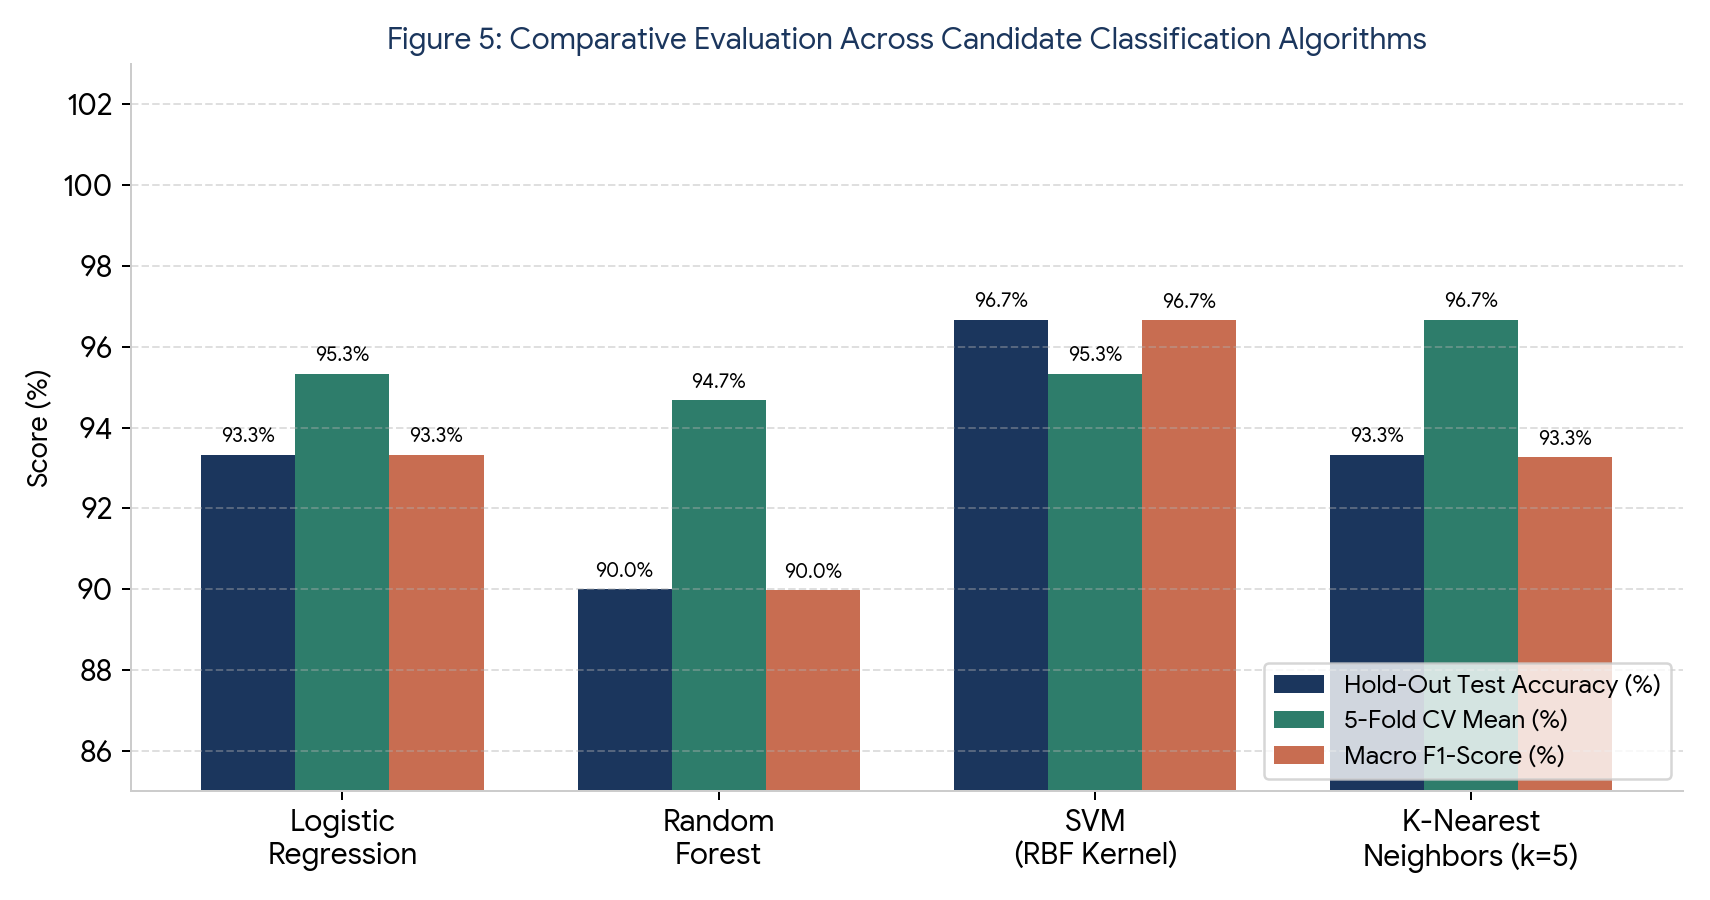

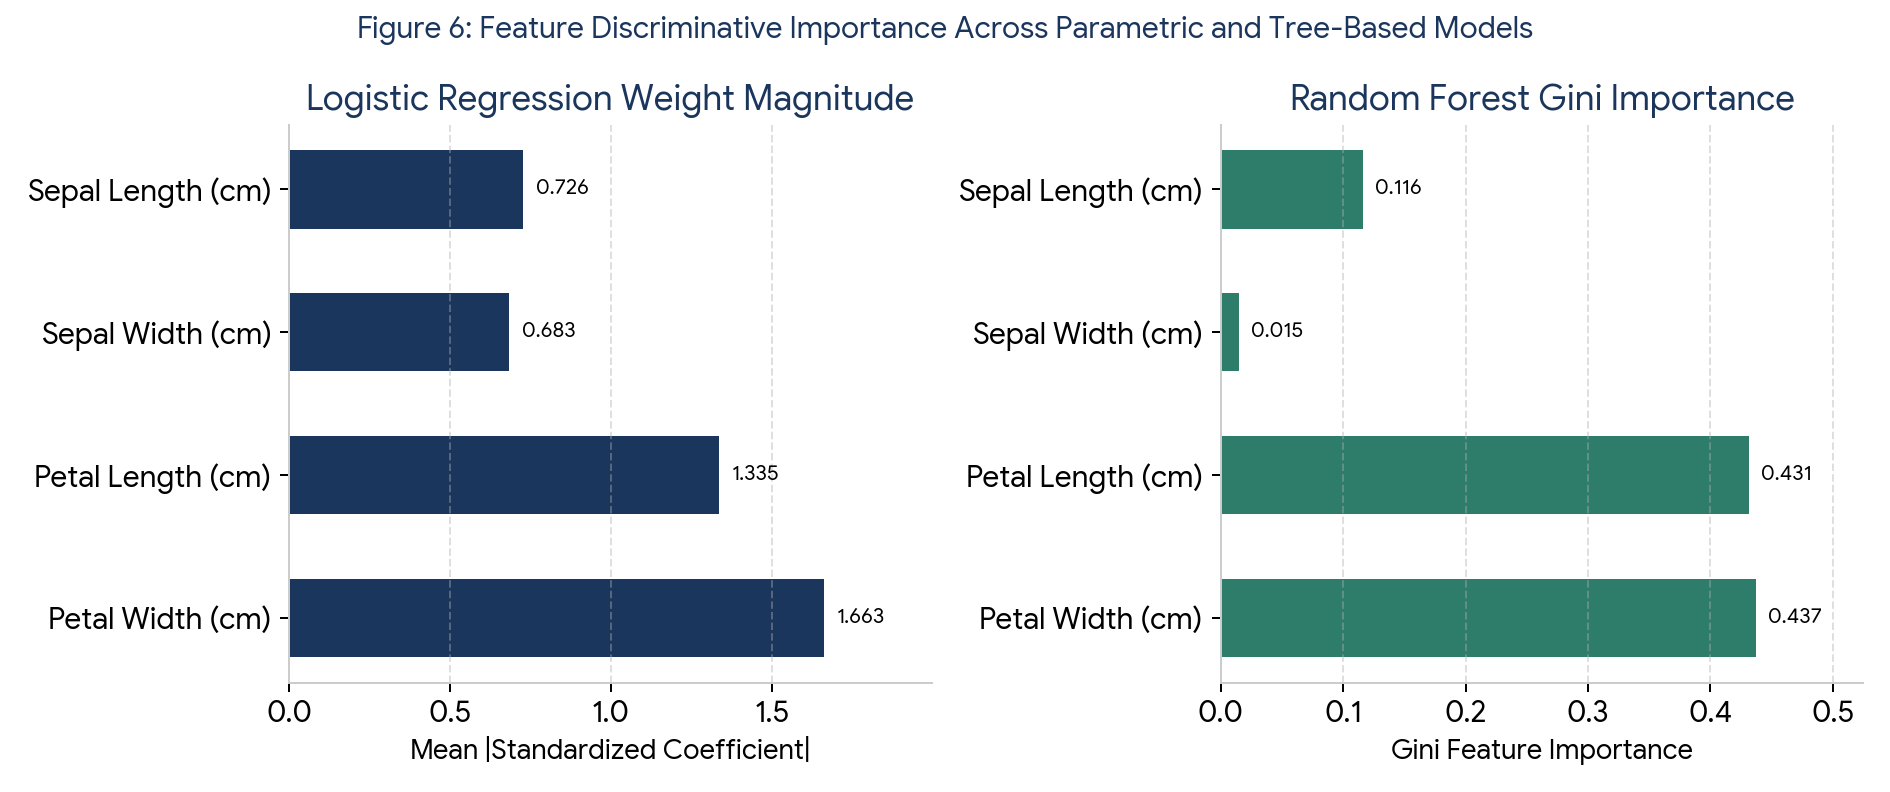

In [4]:
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

primary_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=200, random_state=42))
])
primary_pipeline.fit(X_train, y_train)
y_pred = primary_pipeline.predict(X_test)
y_prob = primary_pipeline.predict_proba(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(primary_pipeline, X, y, cv=cv, scoring='accuracy')
print(f"Hold-Out Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}% | Macro F1: {f1_score(y_test, y_pred, average='macro')*100:.2f}% | OvR ROC-AUC: {roc_auc_score(y_test, y_prob, multi_class='ovr')*100:.2f}% | 5-Fold CV: {cv_scores.mean()*100:.2f}% (+/- {cv_scores.std()*100:.2f}%)")

# Export model parameters for live web app
scaler = primary_pipeline.named_steps['scaler']
clf = primary_pipeline.named_steps['clf']
with open('iris_model_weights.json', 'w') as f:
    json.dump({
        'scaler_mean': np.round(scaler.mean_, 4).tolist(),
        'scaler_scale': np.round(scaler.scale_, 4).tolist(),
        'weights': np.round(clf.coef_, 4).tolist(),
        'intercept': np.round(clf.intercept_, 4).tolist()
    }, f, indent=2)